In [1]:
from langgraph.graph import StateGraph, END, START
from langchain_openai import ChatOpenAI
from typing import TypedDict
from dotenv import load_dotenv

In [2]:
load_dotenv()

True

In [3]:
#  create a state schema

In [4]:
class LLMState(TypedDict):

    question: str
    answer: str

In [8]:
import os

In [10]:
# load the llm

model = ChatOpenAI(
    model = 'gemini-2.5-flash-lite',
    base_url= 'https://openrouter.ai/api/v1',
    api_key= os.getenv("OPENROUTER_API_KEY"),
    temperature= 0.5,
)

In [11]:
# create the node function

In [12]:
def llm_qa(state: LLMState) -> LLMState:

    # extract the question
    question = state['question']

    # prompt with placeholder question
    prompt = f'answer the following question {question}'

    # ask the que to llm
    answer = model.invoke(prompt).content

    # update the answer in the state
    state['answer'] = answer

    return state

In [13]:
# create and compile graph

In [14]:
graph = StateGraph(LLMState)

# add nodes
graph.add_node('llm_qa', llm_qa)

# add edges

graph.add_edge(START, 'llm_qa')
graph.add_edge('llm_qa', END)

In [15]:
workflow = graph.compile()

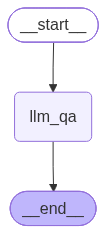

In [16]:
workflow

In [17]:
# execute

In [18]:
intial_state = {'question': 'how far it will take for India to become the Vishwa guru'}

In [19]:
final_state = workflow.invoke(intial_state)

In [21]:
print(final_state['answer'])

The concept of India becoming a "Vishwa Guru" (World Teacher or Global Leader) is a multifaceted aspiration, and there's no single, definitive timeline for its realization. It's not a destination with a fixed arrival date, but rather a continuous process influenced by various factors.

Here's a breakdown of what it entails and the factors that will shape its timeline:

**What does "Vishwa Guru" mean in this context?**

The term "Vishwa Guru" is often interpreted in several ways, and its achievement depends on which interpretation you prioritize:

*   **Economic Powerhouse:** Becoming the world's largest or one of the largest economies, with significant global economic influence.
*   **Technological and Innovation Hub:** Leading in scientific research, technological advancements, and innovation, attracting global talent and investment.
*   **Cultural Influence:** Spreading its rich cultural heritage, philosophy, yoga, and spiritual teachings globally, influencing global thought and prac

## Prompt Chaining Workflow

In [23]:
# creating a blog from the outline generated for a title
# title -> outline -> blog

In [31]:
# state

class BlogState(TypedDict):

    title: str
    outline: str
    blog: str

In [32]:
def create_outline(state: BlogState) -> BlogState:

    title = state['title']

    prompt = f"generate a detailed outline for a blog on the topic {title}"

    outline = model.invoke(prompt).content

    # update the state

    state['outline'] = outline

    return state

In [33]:
def create_blog(state: BlogState) -> BlogState:

    title = state['title']
    outline = state['outline']

    prompt = f"write a detailed blog on the title - {title} using the following outline - {outline}"

    blog = model.invoke(prompt).content

    state['blog'] = blog

    return state

In [34]:
# build and compile

In [35]:
graph = StateGraph(BlogState)

graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)

graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)

workflow = graph.compile()

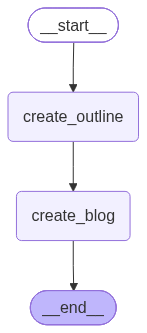

In [36]:
workflow

In [ ]:
intial_state = {'title': 'AI Advancement in Inida'}

final_state = workflow.invoke(intial_state)

print(final_state);

{'title': 'AI Advancement in Inida', 'outline': '## Blog Post Outline: AI Advancement in India - A Nation on the Rise\n\n**Target Audience:** Tech enthusiasts, business leaders, policymakers, students, and anyone interested in India\'s technological progress.\n\n**Overall Tone:** Informative, optimistic, forward-looking, highlighting challenges and opportunities.\n\n---\n\n**I. Catchy Title Options (Choose one or adapt):**\n\n*   AI in India: From Nascent Stages to Global Powerhouse\n*   India\'s AI Revolution: Opportunities, Challenges, and the Road Ahead\n*   The Rise of Artificial Intelligence in India: Shaping the Future of a Billion People\n*   Beyond the Hype: Understanding India\'s Real AI Advancement\n*   India\'s AI Leap: How Technology is Transforming a Nation\n\n**II. Introduction (Hook & Overview)**\n\n*   **Hook:** Start with a compelling statistic, a recent AI breakthrough in India, or a relatable anecdote about AI\'s growing presence.\n    *   *Example:* "Imagine a farme

In [38]:
print(final_state['outline'])

## Blog Outline: AI Advancement in India - A Nation on the Rise

**Blog Title Options:**

* AI in India: From Potential to Powerhouse
* India's AI Revolution: Driving Innovation and Economic Growth
* The Future is Now: Exploring AI Advancement in India
* India's AI Leap: Opportunities, Challenges, and the Road Ahead

**Target Audience:**

* Tech enthusiasts
* Business leaders and entrepreneurs
* Policymakers and government officials
* Students and researchers
* General audience interested in India's technological progress

**Blog Goal:**

To provide a comprehensive overview of the current state, key drivers, impact, challenges, and future trajectory of AI advancement in India.

---

### **I. Introduction (Hook & Overview)**

*   **A. Captivating Hook:**
    *   Start with a compelling statistic about India's tech adoption or AI investment.
    *   Pose a thought-provoking question about India's role in the global AI landscape.
    *   Use a short, impactful anecdote or case study of AI